In [13]:
dataset_path = "DatasetClassification"
classes = ["BlackRot", "Esca", "LeafBlight"]

In [14]:
import os
from PIL import Image
import numpy as np

image_list = []
label_list = []
path_list = [] 

for cl_int, cl in enumerate(classes):
    for img_name in os.listdir(os.path.join(dataset_path, cl)):
        img = Image.open(os.path.join(dataset_path, cl, img_name))
        
        #resize
        img = img.resize((64, 64))

        #convert and turn 1D
        img = np.array(img).flatten()

        image_list.append(img)
        label_list.append(cl_int)
        path_list.append(os.path.join(dataset_path, cl, img_name))



In [15]:
import umap as Umap
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data_standardized = scaler.fit_transform(image_list)

umap = Umap.UMAP(n_neighbors=15, min_dist=0.1, spread=1, n_components=2)
data_umap = umap.fit_transform(data_standardized, label_list)

In [16]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)  # random_state for reproducibility
cluster_labels = kmeans.fit_predict(data_umap)  # This gives cluster assignments for each data point

In [17]:
import plotly.express as px
import pandas as pd

# Create a Pandas DataFrame for Plotly
umap_df = pd.DataFrame(data=data_umap, columns=['x', 'y'])
umap_df['Target'] = pd.Series(label_list)  # Add your target variable (e.g., class labels)
umap_df['Path'] = path_list

# Create a scatter plot with Plotly
fig = px.scatter(umap_df, x='x', y='y', color='Target')
fig.update_layout(title='Umap Visualization',
                 xaxis_title='PC1',
                 yaxis_title='PC2')

In [18]:
import plotly.express as px
import pandas as pd

# Create a Pandas DataFrame for Plotly
knn_df = pd.DataFrame(data=data_umap, columns=['x', 'y'])
knn_df['Target'] = pd.Series(cluster_labels)  # Add your target variable (e.g., class labels)
knn_df['Path'] = path_list

# Create a scatter plot with Plotly
fig = px.scatter(knn_df, x='x', y='y', color='Target')
fig.update_layout(title='Umap Visualization',
                 xaxis_title='PC1',
                 yaxis_title='PC2')

Verify Cluster

            Cluster
Black Rot

In [19]:
clusters_name = ["Cluster 0", "Cluster 1", "Cluster 2"]
classes_name = ["BlackRot", "Esca", "LeafBlight"]

In [20]:
matrix_number_image = [[0, 0, 0], [0, 0, 0], [0, 0, 0]] 
number_image = [[[], [], []], [[], [], []], [[], [], []]] 

for idx, row in umap_df.iterrows():
    matrix_number_image[int(row["Target"])][int(cluster_labels[idx])] += 1  
    number_image[int(row["Target"])][int(cluster_labels[idx])].append(row['Path'])

In [21]:
matrix_number_image

[[17, 55, 21531], [28783, 355, 451], [202, 32719, 603]]

In [22]:
matrix_df = pd.DataFrame(matrix_number_image, columns=clusters_name, index=classes_name )

In [23]:
matrix_df

,Cluster 0,Cluster 1,Cluster 2
BlackRot,17,55,21531
Esca,28783,355,451
LeafBlight,202,32719,603


### Create Folder

In [24]:
import os

os.mkdir("KNNImages")

for cl in classes_name:
    os.mkdir(os.path.join("KNNImages", cl))
    for cluster in clusters_name:
        os.mkdir(os.path.join("KNNImages", cl, cluster))


In [25]:
import shutil

for idx_cl, row in enumerate(number_image):
    for idx_cluster, elems in enumerate(row):
        for path in elems:
            new_path = os.path.join("KNNImages", classes_name[idx_cl] , clusters_name[idx_cluster], path.split("/")[-1])
            shutil.copyfile(path, new_path)

In [26]:
for cl in classes_name:
    for cluster in clusters_name:
        new_path = os.path.join("KNNImages", cl, cluster)
        print(len(os.listdir(new_path)))

    print("\n")

17
55
21531


28783
355
451


202
32719
603




### BlackRot with LeafBligh Cluster

In [27]:
from PIL import Image

im_list = number_image[0][1]  

area_list = [] 

for im_path in im_list:
    im = Image.open(im_path)
    area_list.append(np.array(im).shape[0] * np.array(im).shape[1])

print(sum(area_list)/len(area_list))

423.8545454545455


### Esca with LeafBligh Cluster

In [28]:
from PIL import Image

im_list = number_image[1][1]  

area_list = [] 

for im_path in im_list:
    im = Image.open(im_path)
    area_list.append(np.array(im).shape[0] * np.array(im).shape[1])

print(sum(area_list)/len(area_list))

575.2929577464789


### Histogram per cluster

In [29]:
from matplotlib.pyplot import figure
import matplotlib.pyplot as plt


#======================
def draw_histogram_abs(X1, X2, X3, bin_interval, label, labelX1, labelX2, labelX3):
    # Set a size to the figure (Better Visibility)
    figure(figsize=(20, 10), dpi=80)

    # Create histogram
    fig, ax = plt.subplots(1, 3, figsize=(30, 5))

    i = 0
    for X, labels in zip([X1, X2, X3], [labelX1, labelX2, labelX3]):

        if len(X) == 0:
            continue

        counts, bins, patches = ax[i].hist(X, bins=int(max(X)/bin_interval), range = (0, max(X)), color='skyblue', edgecolor='black')

        ax[i].set_xlabel("Values of the " + str(labels) + " " + str(label))
        ax[i].set_ylabel("Frequency of the " + str(labels) + " " + str(label))

        # Annotate each bin with its frequency
        for count, x in zip(counts, bins):
            # Calculate the position for the text
            height = count
            # Center the label text into middle of bin
            fig_x_axis = x + (bins[1] - bins[0]) / 2
            ax[i].text(fig_x_axis, height, str(int(count)), ha='center', va='bottom', rotation=45)

        i+=1

    plt.subplots_adjust(wspace=0.5)

    plt.show()

In [30]:
from PIL import Image

area_list = [[[], [], []], [[], [], []], [[], [], []]] 

for cl in range(len(number_image)):
    for cluster in range(len(number_image[cl])):
        im_list = number_image[cl][cluster]  

        for im_path in im_list:
            im = Image.open(im_path)
            area_list[cl][cluster].append(np.array(im).shape[0] * np.array(im).shape[1])

In [31]:
for cl in range(len(number_image)):
    for cluster in range(len(number_image[cl])):
        print(len(area_list[cl][cluster]))

17
55
21531
28783
355
451
202
32719
603


<Figure size 1600x800 with 0 Axes>

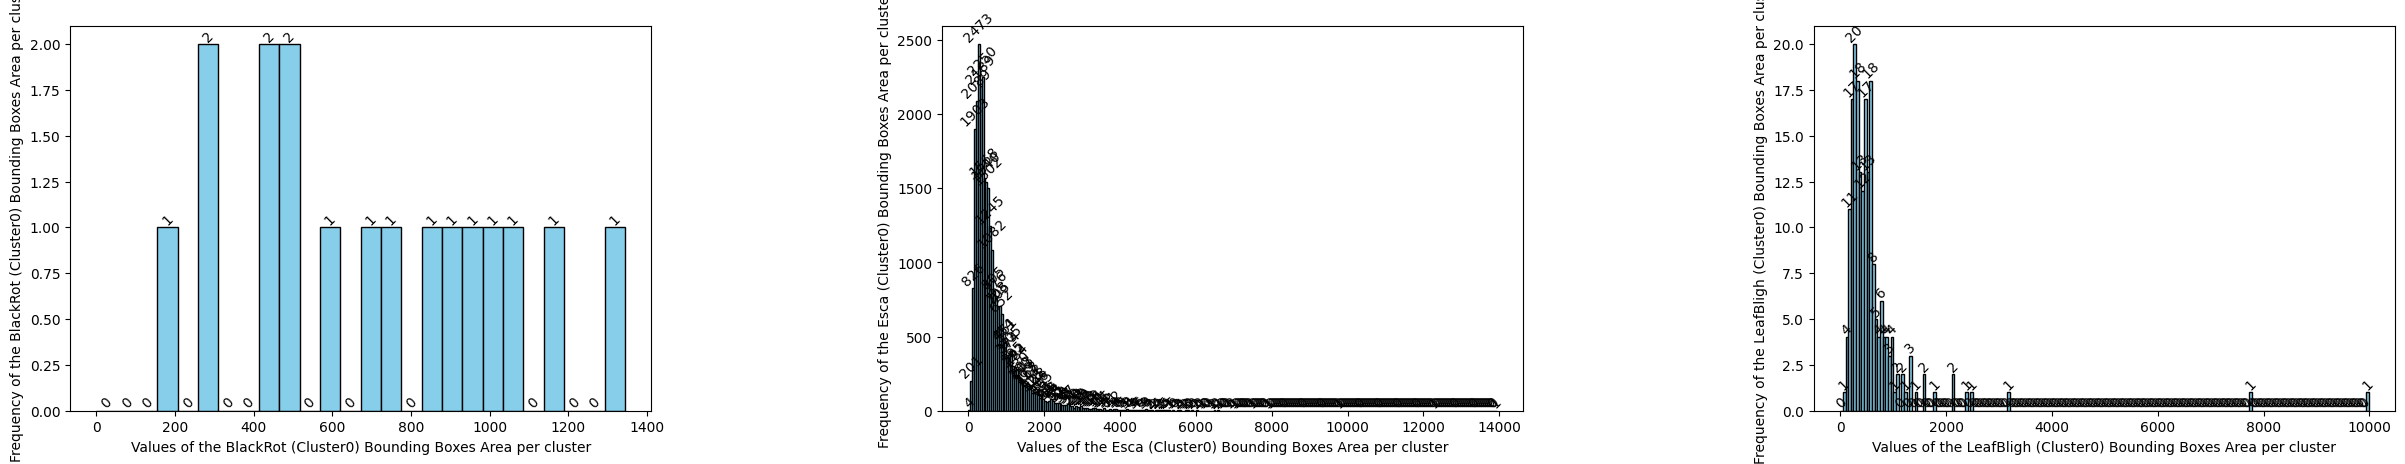

In [32]:
draw_histogram_abs(area_list[0][0], area_list[1][0], area_list[2][0], 50, "Bounding Boxes Area per cluster", "BlackRot (Cluster0)", "Esca (Cluster0)", "LeafBligh (Cluster0)")

<Figure size 1600x800 with 0 Axes>

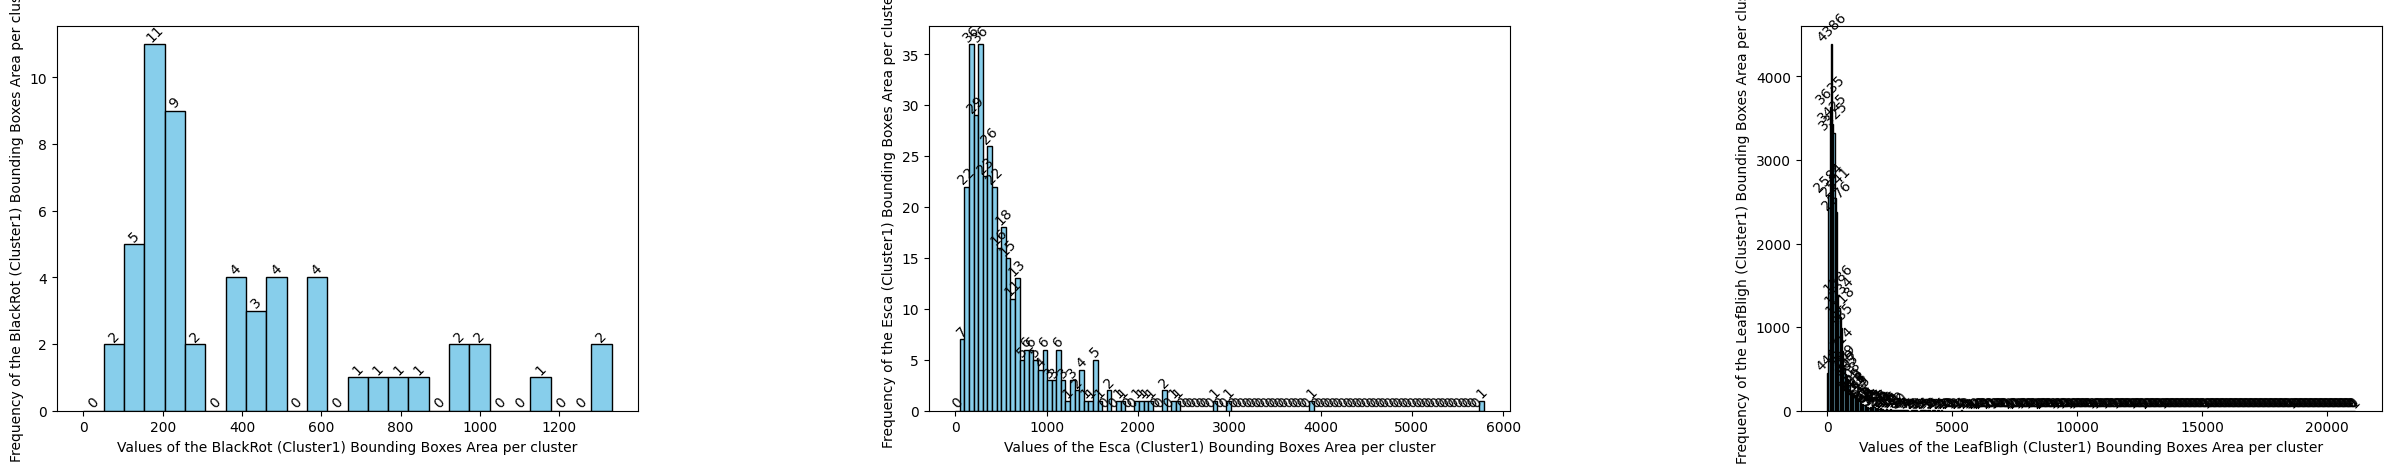

In [33]:
draw_histogram_abs(area_list[0][1], area_list[1][1], area_list[2][1], 50, "Bounding Boxes Area per cluster", "BlackRot (Cluster1)", "Esca (Cluster1)", "LeafBligh (Cluster1)")

<Figure size 1600x800 with 0 Axes>

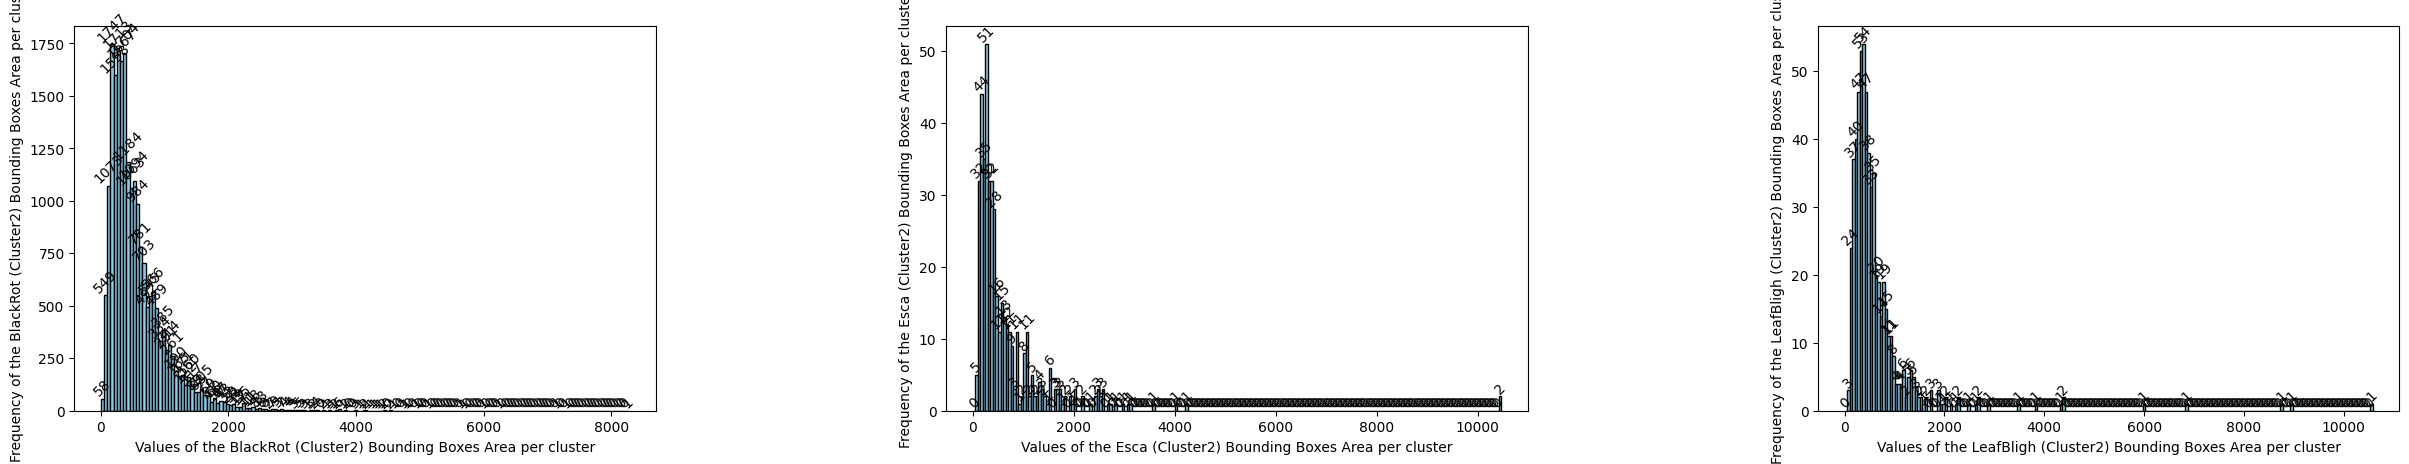

In [34]:
draw_histogram_abs(area_list[0][2], area_list[1][2], area_list[2][2], 50, "Bounding Boxes Area per cluster", "BlackRot (Cluster2)", "Esca (Cluster2)", "LeafBligh (Cluster2)")